# Online News Popularity Prediction: SVM, Decision Tree and PCA

## Project workflow

**Research question:** How does PCA-based dimensionality reduction affect SVM and Decision Tree classification of online news popularity?

**Dataset:** UCI Online News Popularity, 39,644 observations. [Dataset page](https://archive.ics.uci.edu/dataset/332/online+news+popularity).

**Target:** `popular = 1` when `shares > 1400`, otherwise `0`.

Use all rows; exclude `url`, `timedelta`, `shares`, and `popular` from predictors. The split is stratified 60/20/20 with `random_state=42`; Phase 3 uses 5-fold stratified CV on Train. Phase 4 checks PCA sensitivity on Train/Validation, refits frozen models on Train + Validation, and evaluates Test once.

Place the downloaded CSV at `data/OnlineNewsPopularity.csv`.

## 1. Imports, environment and loading the dataset

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid', context='notebook')

print(f'Python: {sys.version.split()[0]}')
for package, version in [
    ('pandas', pd.__version__), ('numpy', np.__version__),
    ('matplotlib', plt.matplotlib.__version__), ('seaborn', sns.__version__),
    ('scikit-learn', sklearn.__version__),
]:
    print(f'{package}: {version}')

candidate_paths = [
    Path('data/OnlineNewsPopularity.csv'),
    Path('../data/OnlineNewsPopularity.csv'),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        'Dataset not found. Download OnlineNewsPopularity.csv from the UCI page '
        'linked above and place it in data/OnlineNewsPopularity.csv.'
    )

df_raw = pd.read_csv(DATA_PATH)
# The supplied CSV headers contain leading spaces; normalize header whitespace only.
df_raw.columns = df_raw.columns.str.strip()
print(f'Loaded: {DATA_PATH.resolve()}')
print(f'Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]:,} columns')

Python: 3.9.12
pandas: 1.4.2
numpy: 1.21.5
matplotlib: 3.5.1
seaborn: 0.11.2
scikit-learn: 1.0.2


Loaded: /Users/yiluo/Desktop/DSA5101_proejct_Online-news-popularity-prediction-based-on-PCA-and-Decision-tree/data/OnlineNewsPopularity.csv
Shape: 39,644 rows × 61 columns


## 2. Dimensions, schema, missingness and duplicates

In [2]:
schema = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'non_null': df_raw.notna().sum(),
    'missing': df_raw.isna().sum(),
    'unique_values': df_raw.nunique(dropna=True),
}).sort_index()
display(schema)

print('Exact duplicate rows:', int(df_raw.duplicated().sum()))
if 'url' in df_raw.columns:
    print('Duplicate URL values:', int(df_raw['url'].duplicated().sum()))
print('Columns with missing values:', int((df_raw.isna().sum() > 0).sum()))
print('Total missing cells:', int(df_raw.isna().sum().sum()))

display(df_raw.describe(include='all').T)

,dtype,non_null,missing,unique_values
LDA_00,float64,39644,0,39337
LDA_01,float64,39644,0,39098
LDA_02,float64,39644,0,39525
LDA_03,float64,39644,0,38963
LDA_04,float64,39644,0,39370
abs_title_sentiment_polarity,float64,39644,0,653
abs_title_subjectivity,float64,39644,0,532
average_token_length,float64,39644,0,30136
avg_negative_polarity,float64,39644,0,13841
avg_positive_polarity,float64,39644,0,27301


Exact duplicate rows: 0
Duplicate URL values: 0
Columns with missing values: 0
Total missing cells: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
url,39644,39644,http://mashable.com/2013/01/07/amazon-instant-...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timedelta,39644.0,NaN,NaN,NaN,354.530471,214.163767,8.0,164.0,339.0,542.0,731.0
n_tokens_title,39644.0,NaN,NaN,NaN,10.398749,2.114037,2.0,9.0,10.0,12.0,23.0
n_tokens_content,39644.0,NaN,NaN,NaN,546.514731,471.107508,0.0,246.0,409.0,716.0,8474.0
n_unique_tokens,39644.0,NaN,NaN,NaN,0.548216,3.520708,0.0,0.47087,0.539226,0.608696,701.0
n_non_stop_words,39644.0,NaN,NaN,NaN,0.996469,5.231231,0.0,1.0,1.0,1.0,1042.0
n_non_stop_unique_tokens,39644.0,NaN,NaN,NaN,0.689175,3.264816,0.0,0.625739,0.690476,0.75463,650.0
num_hrefs,39644.0,NaN,NaN,NaN,10.88369,11.332017,0.0,4.0,8.0,14.0,304.0
num_self_hrefs,39644.0,NaN,NaN,NaN,3.293638,3.855141,0.0,1.0,3.0,4.0,116.0
num_imgs,39644.0,NaN,NaN,NaN,4.544143,8.309434,0.0,1.0,1.0,4.0,128.0


### Data-quality handling

The schema, missingness, and duplicate checks are shown above. Header whitespace is stripped; this phase does not filter or impute rows.

## 3. Target construction and class distribution

,class,definition,count,percentage
0,Unpopular (0),shares ≤ 1400,20082,50.655837
1,Popular (1),shares > 1400,19562,49.344163


Rows exactly at threshold (assigned unpopular): 1592
Observed shares median (descriptive only): 1400.0


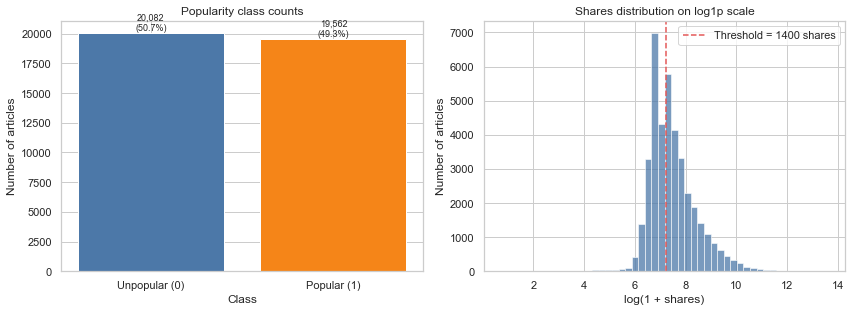

In [3]:
TARGET_SOURCE = 'shares'
POPULARITY_THRESHOLD = 1400
if TARGET_SOURCE not in df_raw.columns:
    raise KeyError(f'Required target column {TARGET_SOURCE!r} is absent.')

shares = pd.to_numeric(df_raw[TARGET_SOURCE], errors='coerce')
if shares.isna().any():
    raise ValueError('The shares target has missing or non-numeric values; resolve before labeling.')

df = df_raw.copy()
df['popular'] = (shares > POPULARITY_THRESHOLD).astype('int8')
class_counts = df['popular'].value_counts().reindex([0, 1], fill_value=0)
class_summary = pd.DataFrame({
    'class': ['Unpopular (0)', 'Popular (1)'],
    'definition': [f'shares ≤ {POPULARITY_THRESHOLD}', f'shares > {POPULARITY_THRESHOLD}'],
    'count': [int(class_counts.loc[0]), int(class_counts.loc[1])],
    'percentage': [100 * class_counts.loc[0] / len(df), 100 * class_counts.loc[1] / len(df)],
})
display(class_summary)
print('Rows exactly at threshold (assigned unpopular):', int((shares == POPULARITY_THRESHOLD).sum()))
print('Observed shares median (descriptive only):', float(shares.median()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(class_summary['class'], class_summary['count'],
           color=['#4C78A8', '#F58518'])
axes[0].set_title('Popularity class counts')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Number of articles')
for i, row in class_summary.iterrows():
    axes[0].text(i, row['count'], f"{row['count']:,}\n({row['percentage']:.1f}%)",
                 ha='center', va='bottom', fontsize=9)

sns.histplot(np.log1p(shares), bins=50, color='#4C78A8', ax=axes[1])
axes[1].axvline(np.log1p(POPULARITY_THRESHOLD), color='#E45756', linestyle='--',
                label=f'Threshold = {POPULARITY_THRESHOLD} shares')
axes[1].set_title('Shares distribution on log1p scale')
axes[1].set_xlabel('log(1 + shares)')
axes[1].set_ylabel('Number of articles')
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Define candidate predictors and exclude target/identifier

In [4]:
# `shares` defines the label and must never enter X. `url` is an article identifier,
# not a generalizable numeric/content predictor, and is excluded from the feature matrix.
EXCLUDED_COLUMNS = {'shares', 'popular', 'url', 'timedelta'}
feature_columns = [c for c in df.columns if c not in EXCLUDED_COLUMNS]
X_eda = df[feature_columns].copy()
y = df['popular'].copy()

print(f'Candidate predictors: {X_eda.shape[1]}')
print('Excluded columns:', sorted(EXCLUDED_COLUMNS.intersection(df.columns)))
print('Excluded non-predictors:', sorted(EXCLUDED_COLUMNS.intersection(df.columns)))
display(pd.DataFrame({
    'feature': feature_columns,
    'dtype': X_eda.dtypes.astype(str).values,
    'n_unique': X_eda.nunique(dropna=True).values,
}).head(70))

Candidate predictors: 58
Excluded columns: ['popular', 'shares', 'timedelta', 'url']
Excluded non-predictors: ['popular', 'shares', 'timedelta', 'url']


,feature,dtype,n_unique
0,n_tokens_title,float64,20
1,n_tokens_content,float64,2406
2,n_unique_tokens,float64,27281
3,n_non_stop_words,float64,1451
4,n_non_stop_unique_tokens,float64,22930
5,num_hrefs,float64,133
6,num_self_hrefs,float64,59
7,num_imgs,float64,91
8,num_videos,float64,53
9,average_token_length,float64,30136


## 5. Exploratory feature analysis

Numeric candidate features: 58
Binary indicator features: 14
Other numeric features: 44


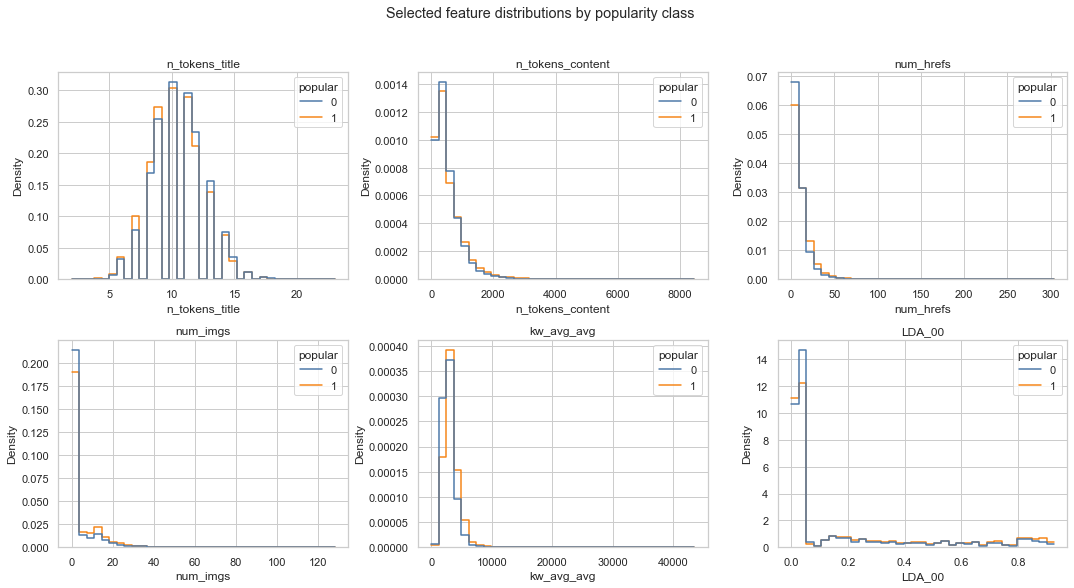

,Pearson correlation with popular label
kw_avg_avg,0.162057
LDA_02,-0.156471
data_channel_is_world,-0.150726
is_weekend,0.137616
data_channel_is_entertainment,-0.110558
data_channel_is_socmed,0.110144
weekday_is_saturday,0.106713
data_channel_is_tech,0.095336
kw_min_avg,0.092386
num_hrefs,0.088362


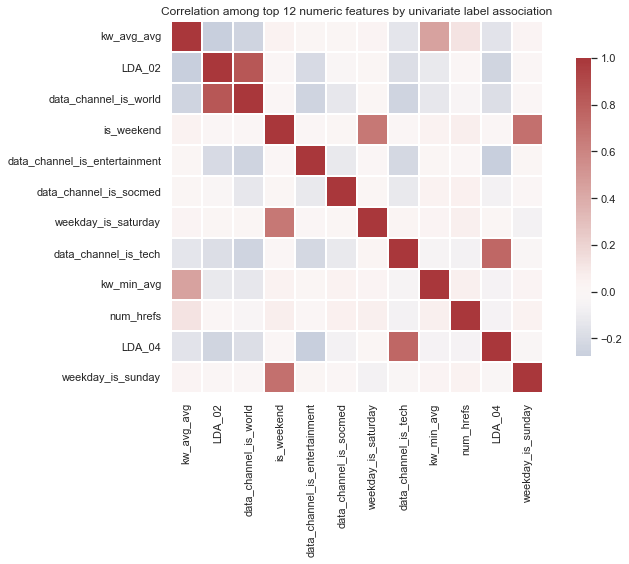

In [5]:
numeric_features = X_eda.select_dtypes(include=np.number).columns.tolist()
binary_features = [c for c in numeric_features if set(X_eda[c].dropna().unique()).issubset({0, 1})]
continuous_features = [c for c in numeric_features if c not in binary_features]
print(f'Numeric candidate features: {len(numeric_features)}')
print(f'Binary indicator features: {len(binary_features)}')
print(f'Other numeric features: {len(continuous_features)}')

# Distribution of selected continuous features. These plots are descriptive, not model selection.
preferred = ['n_tokens_title', 'n_tokens_content', 'num_hrefs', 'num_imgs',
             'kw_avg_avg', 'LDA_00', 'global_sentiment_polarity']
plot_features = [c for c in preferred if c in X_eda.columns]
if len(plot_features) < 4:
    plot_features += [c for c in continuous_features if c not in plot_features][:max(0, 6-len(plot_features))]
plot_features = plot_features[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, plot_features):
    sns.histplot(data=df, x=col, hue='popular', bins=35, stat='density',
                 common_norm=False, element='step', fill=False, ax=ax,
                 palette={0: '#4C78A8', 1: '#F58518'})
    ax.set_title(col)
    ax.set_ylabel('Density')
for ax in axes.flat[len(plot_features):]:
    ax.set_visible(False)
fig.suptitle('Selected feature distributions by popularity class', y=1.02)
plt.tight_layout()
plt.show()

# Univariate association screen for numeric predictors. This is EDA only; it is not
# feature selection and must not be used to tune against the final test set.
numeric_assoc = X_eda[numeric_features].corrwith(y).dropna().sort_values(key=np.abs, ascending=False)
display(numeric_assoc.rename('Pearson correlation with popular label').to_frame().head(15))
top_corr_features = numeric_assoc.head(12).index.tolist()
if top_corr_features:
    corr = X_eda[top_corr_features].corr()
    plt.figure(figsize=(11, 8))
    sns.heatmap(corr, cmap='vlag', center=0, square=True, linewidths=.3,
                cbar_kws={'shrink': .8})
    plt.title('Correlation among top 12 numeric features by univariate label association')
    plt.tight_layout()
    plt.show()

EDA correlations and class-conditioned plots are descriptive; they are not causal evidence or feature-selection rules.

## 6. Preliminary data-leakage and feature-availability audit

In [6]:
audit_rows = [
    ('shares', 'Target leakage', 'Excluded from predictors; directly defines popular.'),
    ('popular', 'Target', 'Excluded from predictors; derived from shares > 1400.'),
    ('url', 'Identifier / UCI non-predictive', 'Excluded from predictors; article URL is an identifier and could encourage memorization.'),
    ('timedelta', 'Non-predictive metadata / UCI non-predictive', 'Excluded from predictors as requested. Not used to filter rows or split data.'),
    ('self_reference_*_shares', 'Potentially time-sensitive aggregate', 'The reference paper describes referenced Mashable article shares as known before publication. Retain only if the construction is confirmed to use earlier articles only.'),
    ('kw_*', 'Potentially time-sensitive aggregate', 'The reference paper describes keyword share aggregates as known before publication. Verify no current/future article outcomes enter these aggregates.'),
    ('remaining content/meta features', 'Prediction-time availability', 'Check each field is observable at the intended prediction point; do not infer availability from column names alone.'),
]
leakage_audit = pd.DataFrame(audit_rows, columns=['field/group', 'risk category', 'Phase 2 decision / verification'])
display(leakage_audit)

suspect_cols = [c for c in X_eda.columns if c.startswith('self_reference_') or c.startswith('kw_')]
print('Potentially time-sensitive candidate columns:', suspect_cols)
print('No timedelta-based filtering or splitting is used in the finalized design.')

,field/group,risk category,Phase 2 decision / verification
0,shares,Target leakage,Excluded from predictors; directly defines pop...
1,popular,Target,Excluded from predictors; derived from shares ...
2,url,Identifier / UCI non-predictive,Excluded from predictors; article URL is an id...
3,timedelta,Non-predictive metadata / UCI non-predictive,Excluded from predictors as requested. Not use...
4,self_reference_*_shares,Potentially time-sensitive aggregate,The reference paper describes referenced Masha...
5,kw_*,Potentially time-sensitive aggregate,The reference paper describes keyword share ag...
6,remaining content/meta features,Prediction-time availability,Check each field is observable at the intended...


Potentially time-sensitive candidate columns: ['kw_min_min', 'kw_max_min', 'kw_avg_min', 'kw_min_max', 'kw_max_max', 'kw_avg_max', 'kw_min_avg', 'kw_max_avg', 'kw_avg_avg', 'self_reference_min_shares', 'self_reference_max_shares', 'self_reference_avg_sharess']
No timedelta-based filtering or splitting is used in the finalized design.


### Leakage controls

- Keep all 39,644 rows. Exclude `url`, `timedelta`, `shares`, and `popular` from predictors; use `shares` only to create the target.
- Fit scaling and PCA inside each training fold/pipeline. Use Validation for comparison and Test only after configurations are frozen.
- The CSV does not timestamp historical share aggregates for referenced articles/keywords, so their availability at publication cannot be confirmed from this file alone.

## 7. Phase 1 summary and reproducibility record

In [7]:
print('Phase 1 completion record')
print(f'- Dataset file: {DATA_PATH.name}')
print(f'- Rows × original columns: {df_raw.shape[0]:,} × {df_raw.shape[1]:,}')
print(f'- Candidate predictors after exclusions: {X_eda.shape[1]}')
print(f'- Missing cells: {int(df_raw.isna().sum().sum()):,}')
print(f'- Exact duplicate rows: {int(df_raw.duplicated().sum()):,}')
print(f'- Target rule: popular = 1 iff shares > {POPULARITY_THRESHOLD}; otherwise 0')
print(f'- Class counts: unpopular={int(class_counts.loc[0]):,}; popular={int(class_counts.loc[1]):,}')
print('- Models trained: none')
print('- PCA fitted: no')

Phase 1 completion record
- Dataset file: OnlineNewsPopularity.csv
- Rows × original columns: 39,644 × 61
- Candidate predictors after exclusions: 58
- Missing cells: 0
- Exact duplicate rows: 0
- Target rule: popular = 1 iff shares > 1400; otherwise 0
- Class counts: unpopular=20,082; popular=19,562
- Models trained: none
- PCA fitted: no


# Phase 2 — Data split and preprocessing

Use all observations and the fixed target. Exclude the target source and non-predictive identifiers from `X`; retain the documented feature-availability caveat for historical share aggregates.

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_SEED = 42
TARGET_SOURCE = 'shares'
POPULARITY_THRESHOLD = 1400
NON_PREDICTIVE_COLUMNS = {'url', 'timedelta', 'shares', 'popular'}

# Use all original rows. No age-based filtering or time-based partitioning.
model_df = df_raw.copy()
model_df['popular'] = (pd.to_numeric(model_df[TARGET_SOURCE]) > POPULARITY_THRESHOLD).astype('int8')
FEATURE_COLUMNS = [c for c in model_df.columns if c not in NON_PREDICTIVE_COLUMNS]
X_all = model_df[FEATURE_COLUMNS].copy()
y_all = model_df['popular'].copy()

assert len(model_df) == len(df_raw) == 39_644
assert not (set(FEATURE_COLUMNS) & NON_PREDICTIVE_COLUMNS)
assert 'timedelta' not in X_all.columns and 'url' not in X_all.columns
print(f'Rows used: {len(model_df):,} (all original observations)')
print(f'Predictors: {len(FEATURE_COLUMNS)}')
print('Excluded from X:', sorted(NON_PREDICTIVE_COLUMNS))
print('Target counts:', y_all.value_counts().sort_index().to_dict())

Rows used: 39,644 (all original observations)
Predictors: 58
Excluded from X: ['popular', 'shares', 'timedelta', 'url']
Target counts: {0: 20082, 1: 19562}


## 9. Reproducible stratified 60 / 20 / 20 split

Two stratified random splits with `random_state=42` create Train, Validation, and Test partitions of 60%, 20%, and 20%. No time-based filtering or splitting is used.

In [9]:
all_indices = model_df.index.to_numpy()
train_idx, holdout_idx = train_test_split(
    all_indices,
    train_size=0.60,
    random_state=RANDOM_SEED,
    stratify=y_all.loc[all_indices],
)
validation_idx, test_idx = train_test_split(
    holdout_idx,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=y_all.loc[holdout_idx],
)

X_train, y_train = X_all.loc[train_idx].copy(), y_all.loc[train_idx].copy()
X_validation, y_validation = X_all.loc[validation_idx].copy(), y_all.loc[validation_idx].copy()
X_test, y_test = X_all.loc[test_idx].copy(), y_all.loc[test_idx].copy()

split_summary = pd.DataFrame([
    {'partition': name, 'rows': len(idx),
     'popular_count': int(y_all.loc[idx].sum()),
     'popular_rate': float(y_all.loc[idx].mean())}
    for name, idx in [('Train', train_idx), ('Validation', validation_idx), ('Test (held out)', test_idx)]
])
display(split_summary)

assert len(train_idx) + len(validation_idx) + len(test_idx) == len(model_df)
assert not (set(train_idx) & set(validation_idx))
assert not (set(train_idx) & set(test_idx))
assert not (set(validation_idx) & set(test_idx))
assert len(train_idx) == 23_786 and len(validation_idx) == 7_929 and len(test_idx) == 7_929
print('Partition shapes:', X_train.shape, X_validation.shape, X_test.shape)
print('The held-out Test partition is reserved for final evaluation only.')

,partition,rows,popular_count,popular_rate
0,Train,23786,11737,0.493442
1,Validation,7929,3912,0.493379
2,Test (held out),7929,3913,0.493505


Partition shapes: (23786, 58) (7929, 58) (7929, 58)
The held-out Test partition is reserved for final evaluation only.


## 10. Stratified K-fold validation on Train

Prepare five shuffled stratified folds from `X_train`, `y_train` only (`random_state=42`). Pipelines fit preprocessing separately within each fold.

In [10]:
N_SPLITS = 5
cv_splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)
train_cv_splits = list(cv_splitter.split(X_train, y_train))

cv_fold_summary = pd.DataFrame([
    {
        'fold': fold_id + 1,
        'fold_train_rows': len(fold_train_idx),
        'fold_validation_rows': len(fold_validation_idx),
        'fold_train_popular_rate': float(y_train.iloc[fold_train_idx].mean()),
        'fold_validation_popular_rate': float(y_train.iloc[fold_validation_idx].mean()),
    }
    for fold_id, (fold_train_idx, fold_validation_idx) in enumerate(train_cv_splits)
])
display(cv_fold_summary)
assert len(train_cv_splits) == N_SPLITS
assert all(set(a).isdisjoint(set(b)) for a, b in train_cv_splits)
print('Five stratified fold index pairs prepared from Train only; no model fitting or scoring performed.')

,fold,fold_train_rows,fold_validation_rows,fold_train_popular_rate,fold_validation_popular_rate
0,1,19028,4758,0.493431,0.493485
1,2,19029,4757,0.493457,0.493378
2,3,19029,4757,0.493457,0.493378
3,4,19029,4757,0.493457,0.493378
4,5,19029,4757,0.493405,0.493588


Five stratified fold index pairs prepared from Train only; no model fitting or scoring performed.


## 11. Baseline and model pipelines

Define the `DummyClassifier` baseline and four requested pipelines. Scalers and PCA remain inside pipelines; this cell does not fit models.

In [11]:
PCA_STARTING_VALUE = 0.95  # initial candidate only; no PCA fit in this phase

pipelines = {
    'dummy_baseline': Pipeline([
        ('classifier', DummyClassifier(strategy='prior')),
    ]),
    'scaled_svc': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LinearSVC(random_state=RANDOM_SEED, max_iter=20000, dual=False)),
    ]),
    'scaled_pca_svc': Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=PCA_STARTING_VALUE, svd_solver='full')),
        ('classifier', LinearSVC(random_state=RANDOM_SEED, max_iter=20000, dual=False)),
    ]),
    'decision_tree': Pipeline([
        ('classifier', DecisionTreeClassifier(random_state=RANDOM_SEED)),
    ]),
    'scaled_pca_decision_tree': Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=PCA_STARTING_VALUE, svd_solver='full')),
        ('classifier', DecisionTreeClassifier(random_state=RANDOM_SEED)),
    ]),
}

display(pd.DataFrame([
    {'experiment': name, 'pipeline_steps': ' → '.join(pipe.named_steps.keys()), 'state': 'unfitted'}
    for name, pipe in pipelines.items()
]))
assert all(not hasattr(pipe.named_steps.get('scaler'), 'mean_') for pipe in pipelines.values())
assert all(not hasattr(pipe.named_steps.get('pca'), 'mean_') for pipe in pipelines.values())
assert all(not hasattr(pipe.named_steps['classifier'], 'classes_') for pipe in pipelines.values())
print('All five pipelines (baseline + four experiments) are defined and unfitted.')

,experiment,pipeline_steps,state
0,dummy_baseline,classifier,unfitted
1,scaled_svc,scaler → classifier,unfitted
2,scaled_pca_svc,scaler → pca → classifier,unfitted
3,decision_tree,classifier,unfitted
4,scaled_pca_decision_tree,scaler → pca → classifier,unfitted


All five pipelines (baseline + four experiments) are defined and unfitted.


## 12. Metrics, tuning, and sensitivity design

Use ROC-AUC as the primary metric. E1 tunes `LinearSVC` over `C=[0.1, 1, 10]`; E3 tunes Decision Tree over `max_depth=[5, 10, 20, None]` and `min_samples_leaf=[1, 5, 10]`, using 5-fold stratified CV on Train. E2 and E4 reuse the selected classifier parameters with `PCA(0.95)` and no additional grid search. E0 is the prior baseline. Phase 4 checks PCA variance targets 0.90, 0.95, and 0.99 before final Test evaluation.

## 13. Reproducible environment

The base Anaconda environment is unchanged. Create the project environment and install pinned dependencies:

```bash
conda create -n dsa5101-news-prediction python=3.9.12
conda activate dsa5101-news-prediction
python -m pip install -r requirements.txt
python -m ipykernel install --user --name dsa5101-news-prediction
```

Use `random_state=42`, the fixed split, target threshold 1400, and all original rows. Do not include the raw dataset in the submission ZIP.

### Phase 2 setup

All 39,644 rows are used; predictors exclude `url`, `timedelta`, `shares`, and `popular`. The fixed split is stratified 60/20/20 (seed 42), with 5-fold CV prepared on Train only.

# Phase 3 — Model training and hyperparameter tuning

## 14. Training and validation protocol

Use the existing stratified split. GridSearchCV sees Train only; each complete pipeline fits scaling/PCA within its CV folds. Compare models on Validation. Keep Test out of model and parameter selection.

## 15. Training-only smoke check

A shallow Decision Tree checks training execution and probability output; this is not a model comparison.

In [12]:
from time import perf_counter
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, cross_val_score

smoke_model = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_SEED)
smoke_model.fit(X_train, y_train)
smoke_probabilities = smoke_model.predict_proba(X_train.iloc[:32])
assert smoke_probabilities.shape == (min(32, len(X_train)), 2)
print('Smoke test passed on the full Training partition:', X_train.shape)
print('Training-only smoke probability shape:', smoke_probabilities.shape)
del smoke_model, smoke_probabilities

Smoke test passed on the full Training partition: (23786, 58)
Training-only smoke probability shape: (32, 2)


## 16. Evaluation helpers

Record CV scores and Validation metrics for each fitted Phase 3 model.

In [13]:
phase3_models = {}
phase3_result_records = []
phase3_fold_score_records = []

def record_experiment(name, fitted_model, best_params, cv_scores, runtime_seconds):
    if hasattr(fitted_model, 'decision_function'):
        validation_scores = fitted_model.decision_function(X_validation)
    else:
        positive_index = list(fitted_model.classes_).index(1)
        validation_scores = fitted_model.predict_proba(X_validation)[:, positive_index]
    validation_predictions = fitted_model.predict(X_validation)

    record = {
        'experiment': name,
        'best_hyperparameters': best_params,
        'mean_cv_roc_auc': float(np.mean(cv_scores)),
        'std_cv_roc_auc': float(np.std(cv_scores, ddof=1)),
        'validation_roc_auc': float(roc_auc_score(y_validation, validation_scores)),
        'validation_accuracy': float(accuracy_score(y_validation, validation_predictions)),
        'validation_precision': float(precision_score(y_validation, validation_predictions, zero_division=0)),
        'validation_recall': float(recall_score(y_validation, validation_predictions, zero_division=0)),
        'validation_f1': float(f1_score(y_validation, validation_predictions, zero_division=0)),
        'training_runtime_seconds': float(runtime_seconds),
        'pca_components_retained': None,
    }
    if 'pca' in fitted_model.named_steps:
        record['pca_components_retained'] = int(fitted_model.named_steps['pca'].n_components_)
        record['pca_explained_variance_ratio'] = float(fitted_model.named_steps['pca'].explained_variance_ratio_.sum())
    else:
        record['pca_explained_variance_ratio'] = None

    phase3_models[name] = fitted_model
    phase3_result_records.append(record)
    for fold_no, fold_auc in enumerate(cv_scores, start=1):
        phase3_fold_score_records.append({'experiment': name, 'fold': fold_no, 'cv_roc_auc': float(fold_auc)})
    display(pd.DataFrame([record]))
    print(f'{name} complete; elapsed training/CV time: {runtime_seconds:.2f} seconds.')


def cv_scores_at_best(search):
    best_idx = search.best_index_
    return [float(search.cv_results_[f'split{fold}_test_score'][best_idx]) for fold in range(N_SPLITS)]


## 17. E0 — DummyClassifier baseline (no GridSearchCV)

In [14]:
e0 = clone(pipelines['dummy_baseline'])
start = perf_counter()
e0_cv_scores = cross_val_score(
    e0, X_train, y_train, scoring='roc_auc', cv=cv_splitter, n_jobs=1, error_score='raise'
)
e0.fit(X_train, y_train)
e0_runtime = perf_counter() - start
record_experiment(
    'E0 DummyClassifier', e0,
    {'classifier__strategy': 'prior'}, e0_cv_scores, e0_runtime
)

,experiment,best_hyperparameters,mean_cv_roc_auc,std_cv_roc_auc,validation_roc_auc,validation_accuracy,validation_precision,validation_recall,validation_f1,training_runtime_seconds,pca_components_retained,pca_explained_variance_ratio
0,E0 DummyClassifier,{'classifier__strategy': 'prior'},0.5,0.0,0.5,0.506621,0.0,0.0,0.0,0.093199,None,None


E0 DummyClassifier complete; elapsed training/CV time: 0.09 seconds.


## 18. E3 — Decision Tree with GridSearchCV

Tune `max_depth` and `min_samples_leaf` on Train; reuse the best parameters for E4.

In [15]:
TREE_PARAM_GRID = {
    'classifier__max_depth': [5, 10, 20, None],
    'classifier__min_samples_leaf': [1, 5, 10],
}
e3_search = GridSearchCV(
    estimator=clone(pipelines['decision_tree']),
    param_grid=TREE_PARAM_GRID,
    scoring='roc_auc',
    cv=cv_splitter,
    refit=True,
    return_train_score=False,
    n_jobs=1,
    pre_dispatch=1,
    error_score='raise',
    verbose=0,
)
start = perf_counter()
e3_search.fit(X_train, y_train)
e3_runtime = perf_counter() - start
e3_best_params = dict(e3_search.best_params_)
e3_cv_scores = cv_scores_at_best(e3_search)
record_experiment(
    'E3 DecisionTreeClassifier', e3_search.best_estimator_,
    e3_best_params, e3_cv_scores, e3_runtime
)

,experiment,best_hyperparameters,mean_cv_roc_auc,std_cv_roc_auc,validation_roc_auc,validation_accuracy,validation_precision,validation_recall,validation_f1,training_runtime_seconds,pca_components_retained,pca_explained_variance_ratio
0,E3 DecisionTreeClassifier,"{'classifier__max_depth': 5, 'classifier__min_...",0.674626,0.00535,0.678363,0.63665,0.637797,0.609918,0.623546,34.939736,None,None


E3 DecisionTreeClassifier complete; elapsed training/CV time: 34.94 seconds.


## 19. E4 — StandardScaler + PCA + Decision Tree

Use `PCA(0.95)` and E3's selected tree parameters. Cross-validate on Train, then evaluate on Validation.

In [16]:
e4 = clone(pipelines['scaled_pca_decision_tree']).set_params(
    pca__n_components=0.95,
    **e3_best_params,
)
start = perf_counter()
e4_cv_scores = cross_val_score(
    e4, X_train, y_train, scoring='roc_auc', cv=cv_splitter, n_jobs=1, error_score='raise'
)
e4.fit(X_train, y_train)
e4_runtime = perf_counter() - start
record_experiment(
    'E4 StandardScaler + PCA + DecisionTreeClassifier', e4,
    dict(e3_best_params, **{'pca__n_components': 0.95}), e4_cv_scores, e4_runtime
)

,experiment,best_hyperparameters,mean_cv_roc_auc,std_cv_roc_auc,validation_roc_auc,validation_accuracy,validation_precision,validation_recall,validation_f1,training_runtime_seconds,pca_components_retained,pca_explained_variance_ratio
0,E4 StandardScaler + PCA + DecisionTreeClassifier,"{'classifier__max_depth': 5, 'classifier__min_...",0.647112,0.009489,0.645014,0.600832,0.584636,0.659509,0.61982,2.766267,36,0.95433


E4 StandardScaler + PCA + DecisionTreeClassifier complete; elapsed training/CV time: 2.77 seconds.


## 20. E1 — StandardScaler + LinearSVC

Tune `C=[0.1, 1, 10]` with 5-fold stratified CV and ROC-AUC. GridSearchCV fits the complete pipeline on Train only.

In [17]:
LINEAR_SVC_PARAM_GRID = {'classifier__C': [0.1, 1, 10]}
e1_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LinearSVC(random_state=RANDOM_SEED, max_iter=20000, dual=False)),
])
e1_search = GridSearchCV(
    estimator=e1_pipeline,
    param_grid=LINEAR_SVC_PARAM_GRID,
    scoring='roc_auc',
    cv=cv_splitter,
    refit=True,
    return_train_score=False,
    n_jobs=1,
    pre_dispatch=1,
    error_score='raise',
    verbose=0,
)
start = perf_counter()
e1_search.fit(X_train, y_train)
e1_runtime = perf_counter() - start
e1_best_params = dict(e1_search.best_params_)
e1_cv_scores = cv_scores_at_best(e1_search)
record_experiment(
    'E1 StandardScaler + LinearSVC', e1_search.best_estimator_,
    e1_best_params, e1_cv_scores, e1_runtime
)

,experiment,best_hyperparameters,mean_cv_roc_auc,std_cv_roc_auc,validation_roc_auc,validation_accuracy,validation_precision,validation_recall,validation_f1,training_runtime_seconds,pca_components_retained,pca_explained_variance_ratio
0,E1 StandardScaler + LinearSVC,{'classifier__C': 10},0.702351,0.005909,0.702196,0.653424,0.653887,0.632157,0.642839,30.592732,None,None


E1 StandardScaler + LinearSVC complete; elapsed training/CV time: 30.59 seconds.


### LinearSVC solver

Use `dual=False` with LinearSVC; the requested C grid, folds, and scoring are unchanged.

## 21. E2 — StandardScaler + PCA + LinearSVC

Use `PCA(0.95)` and E1's best `C`. Cross-validate on Train and compare on Validation; no GridSearchCV is used.

In [18]:
e2 = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('classifier', LinearSVC(
        C=e1_best_params['classifier__C'],
        random_state=RANDOM_SEED,
        max_iter=20000,
        dual=False,
    )),
])
start = perf_counter()
e2_cv_scores = cross_val_score(
    e2, X_train, y_train, scoring='roc_auc', cv=cv_splitter, n_jobs=1, error_score='raise'
)
e2.fit(X_train, y_train)
e2_runtime = perf_counter() - start
record_experiment(
    'E2 StandardScaler + PCA + LinearSVC', e2,
    {'classifier__C': e1_best_params['classifier__C'], 'pca__n_components': 0.95},
    e2_cv_scores, e2_runtime
)

,experiment,best_hyperparameters,mean_cv_roc_auc,std_cv_roc_auc,validation_roc_auc,validation_accuracy,validation_precision,validation_recall,validation_f1,training_runtime_seconds,pca_components_retained,pca_explained_variance_ratio
0,E2 StandardScaler + PCA + LinearSVC,"{'classifier__C': 10, 'pca__n_components': 0.95}",0.691555,0.007665,0.693125,0.64447,0.643627,0.626022,0.634703,1.010882,36,0.95433


E2 StandardScaler + PCA + LinearSVC complete; elapsed training/CV time: 1.01 seconds.


## 22. Phase 3 results

The tables and figures report selected parameters, Training CV, and Validation performance.

,experiment,best_hyperparameters,mean_cv_roc_auc,std_cv_roc_auc,validation_roc_auc,validation_accuracy,validation_precision,validation_recall,validation_f1,training_runtime_seconds,pca_components_retained,pca_explained_variance_ratio
0,E0 DummyClassifier,{'classifier__strategy': 'prior'},0.500000,0.000000,0.500000,0.506621,0.000000,0.000000,0.000000,0.093199,NaN,NaN
1,E1 StandardScaler + LinearSVC,{'classifier__C': 10},0.702351,0.005909,0.702196,0.653424,0.653887,0.632157,0.642839,30.592732,NaN,NaN
2,E2 StandardScaler + PCA + LinearSVC,"{'classifier__C': 10, 'pca__n_components': 0.95}",0.691555,0.007665,0.693125,0.644470,0.643627,0.626022,0.634703,1.010882,36.0,0.95433
3,E3 DecisionTreeClassifier,"{'classifier__max_depth': 5, 'classifier__min_...",0.674626,0.005350,0.678363,0.636650,0.637797,0.609918,0.623546,34.939736,NaN,NaN
4,E4 StandardScaler + PCA + DecisionTreeClassifier,"{'classifier__max_depth': 5, 'classifier__min_...",0.647112,0.009489,0.645014,0.600832,0.584636,0.659509,0.619820,2.766267,36.0,0.95433


fold,1,2,3,4,5
experiment,,,,,
E0 DummyClassifier,0.500000,0.500000,0.500000,0.500000,0.500000
E1 StandardScaler + LinearSVC,0.694099,0.700193,0.703882,0.703241,0.710338
E2 StandardScaler + PCA + LinearSVC,0.685523,0.688066,0.689129,0.690143,0.704917
E3 DecisionTreeClassifier,0.669446,0.670868,0.672968,0.677220,0.682629
E4 StandardScaler + PCA + DecisionTreeClassifier,0.639792,0.636043,0.650074,0.649522,0.660129


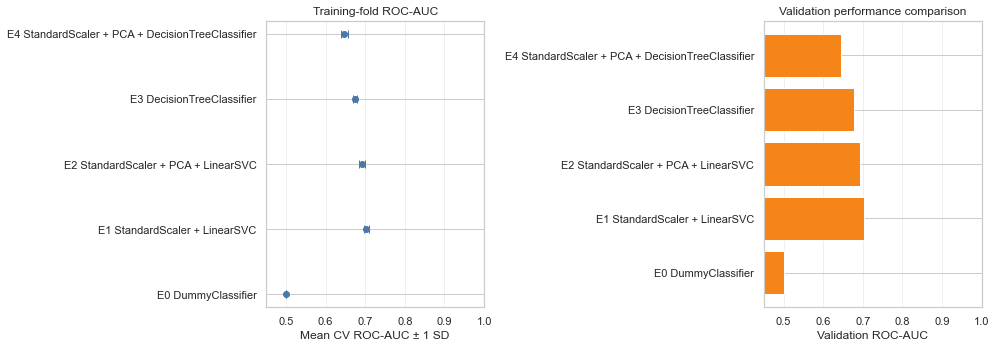

Phase 3 results saved in this executed notebook. Test data was not used.


In [15]:
EXPERIMENT_ORDER = [
    'E0 DummyClassifier',
    'E1 StandardScaler + LinearSVC',
    'E2 StandardScaler + PCA + LinearSVC',
    'E3 DecisionTreeClassifier',
    'E4 StandardScaler + PCA + DecisionTreeClassifier',
]
phase3_results = pd.DataFrame(phase3_result_records).set_index('experiment').loc[EXPERIMENT_ORDER].reset_index()
phase3_fold_results = pd.DataFrame(phase3_fold_score_records)
display(phase3_results)
display(phase3_fold_results.pivot(index='experiment', columns='fold', values='cv_roc_auc').reindex(EXPERIMENT_ORDER))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
y_positions = np.arange(len(phase3_results))
cv_means = phase3_results['mean_cv_roc_auc'].to_numpy()
cv_stds = phase3_results['std_cv_roc_auc'].to_numpy()
axes[0].errorbar(cv_means, y_positions, xerr=cv_stds, fmt='o', capsize=4, color='#4C78A8')
axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(phase3_results['experiment'])
axes[0].set_xlim(0.45, 1.0)
axes[0].set_xlabel('Mean CV ROC-AUC ± 1 SD')
axes[0].set_title('Training-fold ROC-AUC')
axes[0].grid(axis='x', alpha=.3)

axes[1].barh(phase3_results['experiment'], phase3_results['validation_roc_auc'], color='#F58518')
axes[1].set_xlim(0.45, 1.0)
axes[1].set_xlabel('Validation ROC-AUC')
axes[1].set_title('Validation performance comparison')
axes[1].grid(axis='x', alpha=.3)
plt.tight_layout()
plt.show()

print('Phase 3 results saved in this executed notebook. Test data was not used.')

### Phase 3 outputs

Saved results cover E0–E4. The tuned Decision Tree parameters are reused in E4 and Phase 4.

# Phase 4 — Final evaluation and robustness analysis

## 23. Verify and freeze configurations

Verify Phase 3 results and freeze the five configurations before sensitivity analysis or Test evaluation.

In [19]:
# Verify Phase 3 records generated above; recover the tree parameters only when needed.
phase3_verification = pd.DataFrame(phase3_result_records).set_index('experiment')
required_phase3 = [
    'E0 DummyClassifier',
    'E1 StandardScaler + LinearSVC',
    'E2 StandardScaler + PCA + LinearSVC',
    'E3 DecisionTreeClassifier',
    'E4 StandardScaler + PCA + DecisionTreeClassifier',
]
assert set(phase3_verification.index) == set(required_phase3)
assert np.isclose(phase3_verification.loc['E0 DummyClassifier', 'validation_roc_auc'], 0.500000)
assert np.isclose(phase3_verification.loc['E1 StandardScaler + LinearSVC', 'validation_roc_auc'], 0.702196, atol=1e-5)
assert np.isclose(phase3_verification.loc['E2 StandardScaler + PCA + LinearSVC', 'validation_roc_auc'], 0.693125, atol=1e-5)
assert np.isclose(phase3_verification.loc['E3 DecisionTreeClassifier', 'validation_roc_auc'], 0.678363, atol=1e-5)
assert np.isclose(phase3_verification.loc['E4 StandardScaler + PCA + DecisionTreeClassifier', 'validation_roc_auc'], 0.645014, atol=1e-5)
assert e1_best_params == {'classifier__C': 10}
assert e2.named_steps['classifier'].C == 10
assert np.isclose(e2.named_steps['pca'].n_components, 0.95)

if 'e3_best_params' in globals():
    FROZEN_TREE_PARAMS = dict(e3_best_params)
else:
    phase4_tree_search = GridSearchCV(
        estimator=Pipeline([('classifier', DecisionTreeClassifier(random_state=RANDOM_SEED))]),
        param_grid={
            'classifier__max_depth': [5, 10, 20, None],
            'classifier__min_samples_leaf': [1, 5, 10],
        },
        scoring='roc_auc', cv=cv_splitter, refit=True, n_jobs=1,
        return_train_score=False, error_score='raise',
    )
    phase4_tree_search.fit(X_train, y_train)
    FROZEN_TREE_PARAMS = dict(phase4_tree_search.best_params_)
    assert np.isclose(phase4_tree_search.best_score_, phase3_verification.loc['E3 DecisionTreeClassifier', 'mean_cv_roc_auc'], atol=1e-6)

assert FROZEN_TREE_PARAMS.keys() == {'classifier__max_depth', 'classifier__min_samples_leaf'}
assert phase3_verification.loc['E4 StandardScaler + PCA + DecisionTreeClassifier', 'pca_components_retained'] == 36

frozen_configuration_table = pd.DataFrame([
    {'model': 'E0', 'configuration': "DummyClassifier(strategy='prior')"},
    {'model': 'E1', 'configuration': 'StandardScaler + LinearSVC(C=10, dual=False)'},
    {'model': 'E2', 'configuration': 'StandardScaler + PCA(0.95) + LinearSVC(C=10, dual=False)'},
    {'model': 'E3', 'configuration': f'DecisionTreeClassifier({FROZEN_TREE_PARAMS})'},
    {'model': 'E4', 'configuration': f'StandardScaler + PCA(0.95) + DecisionTreeClassifier({FROZEN_TREE_PARAMS})'},
])
display(phase3_verification.reset_index())
display(frozen_configuration_table)
print('Phase 3 validation results verified; frozen tree parameters:', FROZEN_TREE_PARAMS)

,experiment,best_hyperparameters,mean_cv_roc_auc,std_cv_roc_auc,validation_roc_auc,validation_accuracy,validation_precision,validation_recall,validation_f1,training_runtime_seconds,pca_components_retained,pca_explained_variance_ratio
0,E0 DummyClassifier,{'classifier__strategy': 'prior'},0.500000,0.000000,0.500000,0.506621,0.000000,0.000000,0.000000,0.093199,NaN,NaN
1,E3 DecisionTreeClassifier,"{'classifier__max_depth': 5, 'classifier__min_...",0.674626,0.005350,0.678363,0.636650,0.637797,0.609918,0.623546,34.939736,NaN,NaN
2,E4 StandardScaler + PCA + DecisionTreeClassifier,"{'classifier__max_depth': 5, 'classifier__min_...",0.647112,0.009489,0.645014,0.600832,0.584636,0.659509,0.619820,2.766267,36.0,0.95433
3,E1 StandardScaler + LinearSVC,{'classifier__C': 10},0.702351,0.005909,0.702196,0.653424,0.653887,0.632157,0.642839,30.592732,NaN,NaN
4,E2 StandardScaler + PCA + LinearSVC,"{'classifier__C': 10, 'pca__n_components': 0.95}",0.691555,0.007665,0.693125,0.644470,0.643627,0.626022,0.634703,1.010882,36.0,0.95433


,model,configuration
0,E0,DummyClassifier(strategy='prior')
1,E1,"StandardScaler + LinearSVC(C=10, dual=False)"
2,E2,"StandardScaler + PCA(0.95) + LinearSVC(C=10, d..."
3,E3,DecisionTreeClassifier({'classifier__max_depth...
4,E4,StandardScaler + PCA(0.95) + DecisionTreeClass...


Phase 3 validation results verified; frozen tree parameters: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 10}


## 24. PCA sensitivity (Train and Validation only)

Compare `n_components=[0.90, 0.95, 0.99]` with classifier parameters fixed. CV uses Train; Validation reports sensitivity. Test is not used here.

,model,variance_target,components_retained,actual_explained_variance,training_cv_roc_auc_mean,training_cv_roc_auc_std,validation_roc_auc
0,E2 LinearSVC,0.90,30,0.901490,0.689543,0.007576,0.691403
1,E2 LinearSVC,0.95,36,0.954330,0.691555,0.007665,0.693125
2,E2 LinearSVC,0.99,45,0.992188,0.694340,0.008057,0.694810
3,E4 Decision Tree,0.90,30,0.901490,0.647067,0.009433,0.645315
4,E4 Decision Tree,0.95,36,0.954330,0.647112,0.009489,0.645014
5,E4 Decision Tree,0.99,45,0.992188,0.646926,0.009432,0.641156


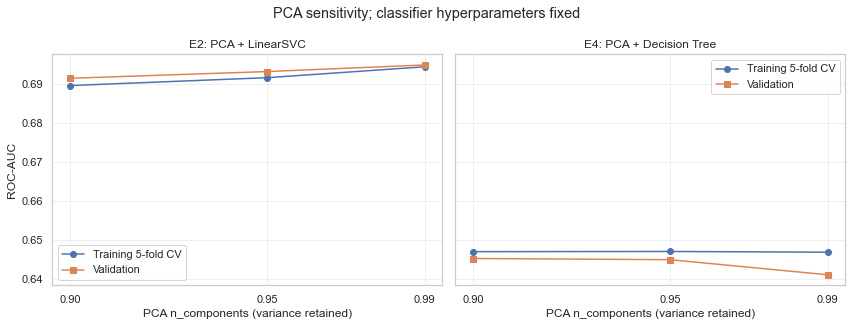

In [20]:
PCA_SENSITIVITY_VALUES = [0.90, 0.95, 0.99]
pca_sensitivity_records = []

def positive_class_score(fitted_pipeline, X):
    if hasattr(fitted_pipeline, 'decision_function'):
        return fitted_pipeline.decision_function(X)
    positive_index = list(fitted_pipeline.classes_).index(1)
    return fitted_pipeline.predict_proba(X)[:, positive_index]

for model_name in ['E2 LinearSVC', 'E4 Decision Tree']:
    for variance_fraction in PCA_SENSITIVITY_VALUES:
        if model_name == 'E2 LinearSVC':
            sensitivity_model = Pipeline([
                ('scaler', StandardScaler()),
                ('pca', PCA(n_components=variance_fraction, svd_solver='full')),
                ('classifier', LinearSVC(C=10, random_state=RANDOM_SEED, max_iter=20000, dual=False)),
            ])
        else:
            sensitivity_model = Pipeline([
                ('scaler', StandardScaler()),
                ('pca', PCA(n_components=variance_fraction, svd_solver='full')),
                ('classifier', DecisionTreeClassifier(
                    max_depth=FROZEN_TREE_PARAMS['classifier__max_depth'],
                    min_samples_leaf=FROZEN_TREE_PARAMS['classifier__min_samples_leaf'],
                    random_state=RANDOM_SEED,
                )),
            ])
        fold_auc = cross_val_score(
            sensitivity_model, X_train, y_train,
            scoring='roc_auc', cv=cv_splitter, n_jobs=1, error_score='raise',
        )
        sensitivity_model.fit(X_train, y_train)
        validation_auc = roc_auc_score(y_validation, positive_class_score(sensitivity_model, X_validation))
        pca_fit = sensitivity_model.named_steps['pca']
        pca_sensitivity_records.append({
            'model': model_name,
            'variance_target': variance_fraction,
            'components_retained': int(pca_fit.n_components_),
            'actual_explained_variance': float(pca_fit.explained_variance_ratio_.sum()),
            'training_cv_roc_auc_mean': float(np.mean(fold_auc)),
            'training_cv_roc_auc_std': float(np.std(fold_auc, ddof=1)),
            'validation_roc_auc': float(validation_auc),
        })

pca_sensitivity = pd.DataFrame(pca_sensitivity_records)
display(pca_sensitivity)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, model_name, title in zip(axes, ['E2 LinearSVC', 'E4 Decision Tree'], ['E2: PCA + LinearSVC', 'E4: PCA + Decision Tree']):
    subset = pca_sensitivity[pca_sensitivity['model'] == model_name]
    ax.plot(subset['variance_target'], subset['training_cv_roc_auc_mean'], marker='o', label='Training 5-fold CV')
    ax.plot(subset['variance_target'], subset['validation_roc_auc'], marker='s', label='Validation')
    ax.set_xticks(PCA_SENSITIVITY_VALUES)
    ax.set_xlabel('PCA n_components (variance retained)')
    ax.set_title(title)
    ax.grid(alpha=.3)
    ax.legend()
axes[0].set_ylabel('ROC-AUC')
fig.suptitle('PCA sensitivity; classifier hyperparameters fixed')
fig.tight_layout()
Path('figures').mkdir(exist_ok=True)
fig.savefig('figures/phase4_pca_sensitivity.png', dpi=200, bbox_inches='tight')
plt.show()

## 25. Refit and final Test evaluation

Refit all five frozen pipelines on Train + Validation. Evaluate Test once; subsequent plots reuse the stored predictions and scores.

In [21]:
from sklearn.metrics import confusion_matrix, roc_curve

X_train_validation = pd.concat([X_train, X_validation]).sort_index()
y_train_validation = pd.concat([y_train, y_validation]).sort_index()
assert len(X_train_validation) == 31_715

phase4_models = {
    'E0 DummyClassifier': Pipeline([
        ('classifier', DummyClassifier(strategy='prior')),
    ]),
    'E1 StandardScaler + LinearSVC': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LinearSVC(C=10, random_state=RANDOM_SEED, max_iter=20000, dual=False)),
    ]),
    'E2 StandardScaler + PCA + LinearSVC': Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=0.95, svd_solver='full')),
        ('classifier', LinearSVC(C=10, random_state=RANDOM_SEED, max_iter=20000, dual=False)),
    ]),
    'E3 DecisionTreeClassifier': Pipeline([
        ('classifier', DecisionTreeClassifier(
            max_depth=FROZEN_TREE_PARAMS['classifier__max_depth'],
            min_samples_leaf=FROZEN_TREE_PARAMS['classifier__min_samples_leaf'],
            random_state=RANDOM_SEED,
        )),
    ]),
    'E4 StandardScaler + PCA + DecisionTreeClassifier': Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=0.95, svd_solver='full')),
        ('classifier', DecisionTreeClassifier(
            max_depth=FROZEN_TREE_PARAMS['classifier__max_depth'],
            min_samples_leaf=FROZEN_TREE_PARAMS['classifier__min_samples_leaf'],
            random_state=RANDOM_SEED,
        )),
    ]),
}
for fitted_pipeline in phase4_models.values():
    fitted_pipeline.fit(X_train_validation, y_train_validation)

# Materialize Test features and labels only now, after all model fitting is complete.
X_test = X_all.loc[test_idx].copy()
y_test = y_all.loc[test_idx].copy()

# One final held-out Test evaluation. No model/configuration selection follows this cell.
phase4_test_records = []
phase4_test_predictions = {}
phase4_test_scores = {}
phase4_confusion_matrices = {}
for model_name, fitted_pipeline in phase4_models.items():
    predictions = fitted_pipeline.predict(X_test)
    scores = positive_class_score(fitted_pipeline, X_test)
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    phase4_test_predictions[model_name] = predictions
    phase4_test_scores[model_name] = scores
    phase4_confusion_matrices[model_name] = matrix
    phase4_test_records.append({
        'model': model_name,
        'test_roc_auc': float(roc_auc_score(y_test, scores)),
        'test_accuracy': float(accuracy_score(y_test, predictions)),
        'test_precision': float(precision_score(y_test, predictions, zero_division=0)),
        'test_recall': float(recall_score(y_test, predictions, zero_division=0)),
        'test_f1': float(f1_score(y_test, predictions, zero_division=0)),
        'true_negative': int(matrix[0, 0]),
        'false_positive': int(matrix[0, 1]),
        'false_negative': int(matrix[1, 0]),
        'true_positive': int(matrix[1, 1]),
    })
phase4_test_results = pd.DataFrame(phase4_test_records)
display(phase4_test_results)
print('Final test evaluation completed once after all configurations were frozen.')

,model,test_roc_auc,test_accuracy,test_precision,test_recall,test_f1,true_negative,false_positive,false_negative,true_positive
0,E0 DummyClassifier,0.500000,0.506495,0.000000,0.000000,0.000000,4016,0,3913,0
1,E1 StandardScaler + LinearSVC,0.690563,0.641695,0.643162,0.615385,0.628967,2680,1336,1505,2408
2,E2 StandardScaler + PCA + LinearSVC,0.678535,0.626308,0.627005,0.599284,0.612832,2621,1395,1568,2345
3,E3 DecisionTreeClassifier,0.669628,0.631227,0.618727,0.658574,0.638029,2428,1588,1336,2577
4,E4 StandardScaler + PCA + DecisionTreeClassifier,0.639701,0.595031,0.585777,0.612573,0.598876,2321,1695,1516,2397


Final test evaluation completed once after all configurations were frozen.


## 26. Evaluation figures

ROC curves, model comparison, and confusion matrices use the saved final Test predictions and scores.

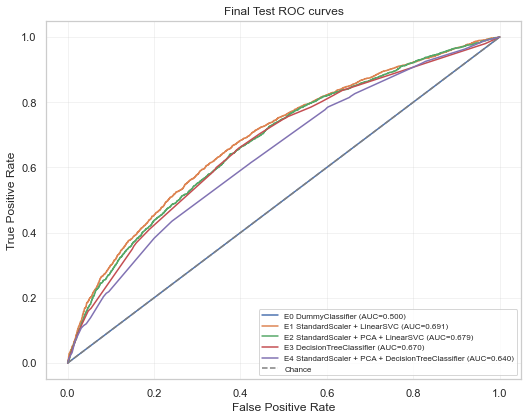

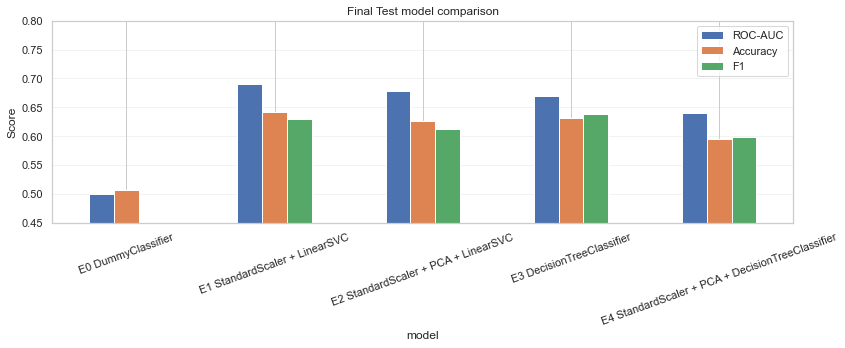

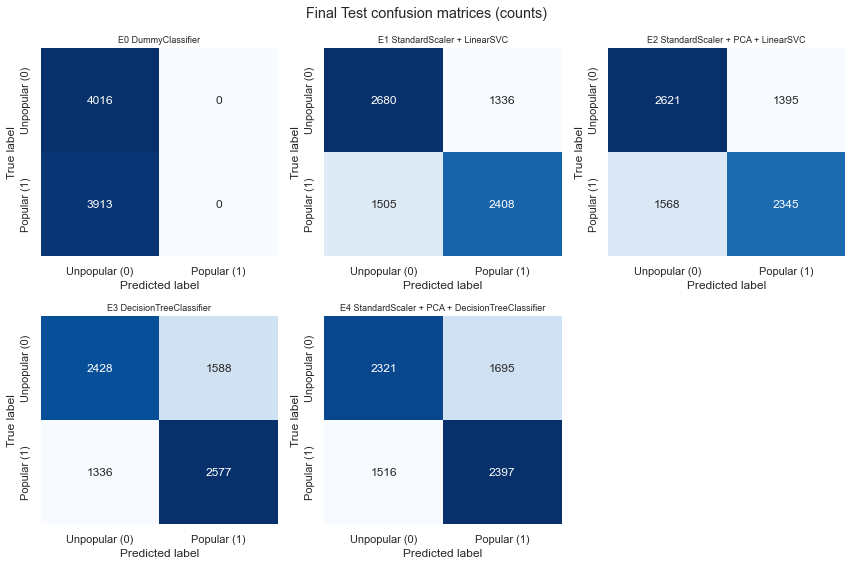

In [22]:
# ROC curves
fig, ax = plt.subplots(figsize=(7.5, 6))
for model_name, scores in phase4_test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc_value = phase4_test_results.loc[phase4_test_results['model'] == model_name, 'test_roc_auc'].iloc[0]
    ax.plot(fpr, tpr, label=f'{model_name} (AUC={auc_value:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='Final Test ROC curves')
ax.legend(loc='lower right', fontsize=8)
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig('figures/phase4_test_roc_curves.png', dpi=200, bbox_inches='tight')
plt.show()

# Side-by-side model comparison
comparison_metrics = ['test_roc_auc', 'test_accuracy', 'test_f1']
comparison_labels = ['ROC-AUC', 'Accuracy', 'F1']
plot_data = phase4_test_results.set_index('model')[comparison_metrics].rename(columns=dict(zip(comparison_metrics, comparison_labels)))
ax = plot_data.plot(kind='bar', figsize=(12, 5), ylim=(0.45, 0.80), rot=20)
ax.set_ylabel('Score')
ax.set_title('Final Test model comparison')
ax.grid(axis='y', alpha=.25)
plt.tight_layout()
plt.savefig('figures/phase4_test_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

# Raw-count confusion matrices
model_names = list(phase4_models)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, model_name in zip(axes.flat, model_names):
    sns.heatmap(
        phase4_confusion_matrices[model_name], annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=['Unpopular (0)', 'Popular (1)'],
        yticklabels=['Unpopular (0)', 'Popular (1)'], ax=ax,
    )
    ax.set_title(model_name, fontsize=9)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
axes.flat[-1].axis('off')
fig.suptitle('Final Test confusion matrices (counts)')
fig.tight_layout()
fig.savefig('figures/phase4_test_confusion_matrices.png', dpi=200, bbox_inches='tight')
plt.show()

## 27. Phase 4 outputs

The sensitivity table, final Test metrics, and evaluation figures are saved above. Detailed interpretation, limitations, and conclusions are reserved for `report.pdf`.

### References

- Fernandes, K., Vinagre, P., & Cortez, P. (2015). *A Proactive Intelligent Decision Support System for Predicting the Popularity of Online News*. EPIA 2015, LNAI 9273, 535–546. https://doi.org/10.1007/978-3-319-23485-4_53
- UCI Machine Learning Repository. *Online News Popularity*. https://archive.ics.uci.edu/dataset/332/online+news+popularity
- Course project requirements: `instructions/project_requirements.md`.